In [33]:
from pathlib import Path
from sqlalchemy import create_engine
import pandas as pd

engine = create_engine("sqlite:///../data/coyuntura.db")

def consultar(sql):
    """Ejecuta una consulta y devuelve el resultado como DataFrame."""
    return pd.read_sql(sql, engine, parse_dates=["fecha"])

In [34]:
consulta = Path("../sql/04_series_jorge.sql").read_text(encoding="utf-8")
df = consultar(consulta)
df.head()

,nombre,fecha,valor,unidad
0,IPC Estados Unidos (índice),2010-01-01,217.488,índice
1,IPC Estados Unidos (índice),2010-02-01,217.281,índice
2,IPC Estados Unidos (índice),2010-03-01,217.353,índice
3,IPC Estados Unidos (índice),2010-04-01,217.403,índice
4,IPC Estados Unidos (índice),2010-05-01,217.290,índice


In [35]:
print("Filas totales:", len(df))
df.groupby("nombre")["valor"].count()

Filas totales: 799


nombre
IPC Estados Unidos (índice)                200
Tasa de desocupación                       198
Índice de precios al productor (EE.UU.)    201
Índice de remuneraciones (var. anual)      200
Name: valor, dtype: int64

In [36]:
df.dtypes

nombre            object
fecha     datetime64[ns]
valor            float64
unidad            object
dtype: object

In [37]:
def consultar(sql):
    """Ejecuta una consulta y devuelve el resultado como DataFrame."""
    return pd.read_sql(sql, engine, parse_dates=["fecha"])

In [38]:
tabla = df.pivot(index="fecha", columns="nombre", values="valor")
tabla.tail()

nombre,IPC Estados Unidos (índice),Tasa de desocupación,Índice de precios al productor (EE.UU.),Índice de remuneraciones (var. anual)
fecha,,,,
2026-05-01,333.979,9.437821,290.281,7.341934
2026-06-01,332.568,9.440585,286.037,7.746356
2026-07-01,332.813,9.529267,284.973,7.809709
2026-08-01,334.131,9.640319,287.735,7.642374
2026-09-01,336.298,NaN,295.708,NaN


In [39]:
tabla["IPC EE.UU. a/a"] = tabla["IPC Estados Unidos (índice)"].pct_change(12) * 100
tabla["PPI EE.UU. a/a"] = tabla["Índice de precios al productor (EE.UU.)"].pct_change(12) * 100

tabla[["IPC EE.UU. a/a", "PPI EE.UU. a/a"]].tail(6).round(2)

C:\Users\jorge\AppData\Local\Temp\ipykernel_113640\1772151895.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  tabla["IPC EE.UU. a/a"] = tabla["IPC Estados Unidos (índice)"].pct_change(12) * 100


nombre,IPC EE.UU. a/a,PPI EE.UU. a/a
fecha,,
2026-04-01,3.78,9.42
2026-05-01,4.17,12.22
2026-06-01,3.46,9.81
2026-07-01,3.30,8.62
2026-08-01,3.35,9.78
2026-09-01,3.72,12.84


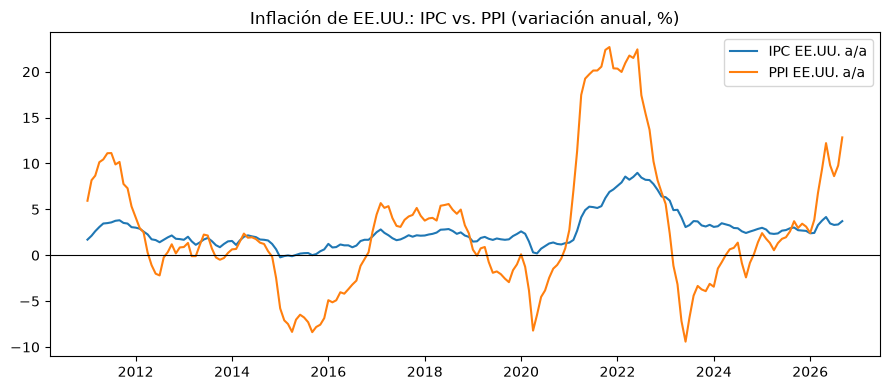

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla["IPC EE.UU. a/a"], label="IPC EE.UU. a/a")
ax.plot(tabla["PPI EE.UU. a/a"], label="PPI EE.UU. a/a")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Inflación de EE.UU.: IPC vs. PPI (variación anual, %)")
ax.legend()
plt.tight_layout()
plt.show()

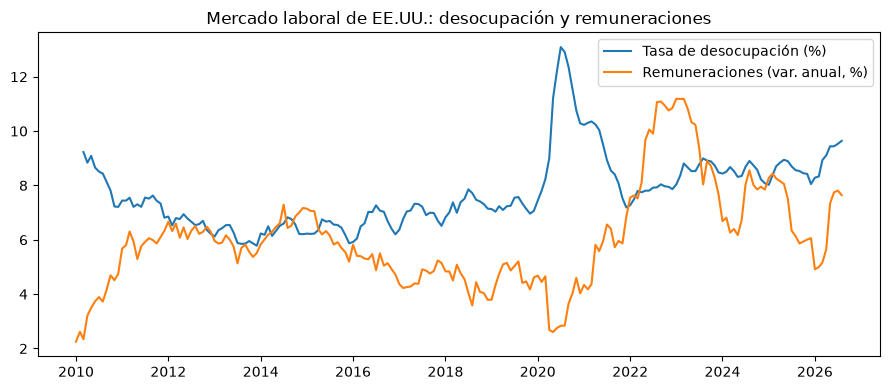

In [41]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla["Tasa de desocupación"], label="Tasa de desocupación (%)")
ax.plot(tabla["Índice de remuneraciones (var. anual)"], label="Remuneraciones (var. anual, %)")
ax.set_title("Mercado laboral de EE.UU.: desocupación y remuneraciones")
ax.legend()
plt.tight_layout()
plt.show()

## Lectura de coyuntura: variables externas de EE.UU.

- El IPC de EE.UU. está entre 3,3 % y 4,2 % anual y subió a 3,72 % en septiembre de 2026.
- El PPI es mucho más volátil que el IPC y hoy está en 12,8 %. En 2021-2022 también subió mucho, y el IPC subió después.
- La desocupación subió a 9,6 % en 2026. Las remuneraciones crecen 7,6 % anual, bastante más que en 2025.
- Estas series entran al proyecto como posibles variables explicativas de la inflación chilena. Más adelante revisaremos si realmente se relacionan.